### 动手训练第一个神经网络
现在我们编写一个完整的 PyTorch 训练程序。

任务是：给定两个数 \(x_1,x_2\)，判断它们是否满足：
\[
x_1+x_2>0
\]

这是一个二分类问题。

例如：
输入	标签
(2, 3)	1
(-2, -3)	0
(1, -2)	0
(-1, 3)	1

我们不手写判断规则，而是让神经网络从训练数据中学习。

In [19]:
from typing import Any

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 设置随机种子
torch.manual_seed(42)

# 选择设备
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Training device: ", device)

# 生成数据
# randn 生成 均值为0, 方差为1的标准正态分布数据
# 第一行创建一个形状为 [10000, 2] 的 Tensor。
#
# 其中：
# - 10000：样本数量。
# - 2：每个样本有两个特征。
# - torch.randn()：从标准正态分布生成随机数。
# 第二行先根据规则产生布尔标签，再转换为浮点数，并增加一个维度。
#
# 最终：
# X.shape = [10000, 2]
# y.shape = [10000, 1]
#
# 为什么需要 unsqueeze(1)？
# 因为我们的神经网络输出形状为 [batch_size, 1]，而 BCEWithLogitsLoss 要求预测值和目标标签的形状一致。
X = torch.randn(10000, 2)
y = (X[:, 0] + X[:, 1] > 0).float().unsqueeze(1)

# 划分训练集和测试集
X_train, X_val = X[:8000], X[8000:]
y_train, y_val = y[:8000], y[8000:]

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=64,
    shuffle=True,
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=256,
    shuffle=True,
)

# 定义神经网络
class SimpleNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.network(x)

model = SimpleNet().to(device)

# 损失函数和优化器
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 训练
epochs = 10

for epoch in range(epochs):
    model.train()

    train_loss = 0.0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        # 清除上一轮梯度
        optimizer.zero_grad()

        # 前向传播
        logist = model(inputs)

        # 计算损失
        loss = criterion(logist, targets)

        # 反向传播
        loss.backward()

        # 更新参数
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)

    # 验证
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = model(inputs)
            predictions = (logits > 0).float()

            correct += (predictions == targets).sum().item()
            total += targets.numel()

    accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Val Accuracy: {accuracy:.4f}"
    )

# 9. 保存模型
torch.save(model.state_dict(), "model.pt")
print("Model saved to model.pt")

Training device:  cuda
Epoch 1/10 | Loss: 0.6667 | Val Accuracy: 0.8330
Epoch 2/10 | Loss: 0.5067 | Val Accuracy: 0.9190
Epoch 3/10 | Loss: 0.3400 | Val Accuracy: 0.9765
Epoch 4/10 | Loss: 0.2189 | Val Accuracy: 0.9870
Epoch 5/10 | Loss: 0.1540 | Val Accuracy: 0.9955
Epoch 6/10 | Loss: 0.1195 | Val Accuracy: 0.9975
Epoch 7/10 | Loss: 0.0989 | Val Accuracy: 0.9975
Epoch 8/10 | Loss: 0.0853 | Val Accuracy: 0.9960
Epoch 9/10 | Loss: 0.0756 | Val Accuracy: 0.9975
Epoch 10/10 | Loss: 0.0684 | Val Accuracy: 0.9990
Model saved to model.pt


In [ ]:
# y = wx + b
# 权重 (w)：决定直线有多陡。
# 偏置 (b)：决定直线上下移动多少。

### 神经网络的五个核心概念

#### 线性层

In [20]:
# y^ = wx + b
# 在PyTorch中可以直接写成
import torch
from torch import nn

model = nn.Linear(1,1)
x = torch.tensor([3.0])
y = model(x)
y

# nn.Linear(1, 1) 表示：
# - 接收 1 个输入特征。
# - 输出 1 个数值。
# - 内部自动创建权重和偏置。



tensor([-1.2503], grad_fn=<UnsafeViewBackward0>)

In [22]:
import torch
from torch import nn

layer = nn.Linear(3, 2)

print(layer.weight)
print(layer.bias)
print(layer.weight.shape)
print(layer.bias.shape)

Parameter containing:
tensor([[-0.5290,  0.0591, -0.1553],
        [-0.0063,  0.1835,  0.1605]], requires_grad=True)
Parameter containing:
tensor([-0.0922,  0.0921], requires_grad=True)
torch.Size([2, 3])
torch.Size([2])


In [23]:
import torch
from torch import nn

layer = nn.Linear(3, 2)

with torch.no_grad():
    layer.weight.copy_(torch.tensor([
        [1.0, 2.0, 3.0],
        [4.0, 5.0, 6.0]
    ]))

    layer.bias.copy_(torch.tensor([1.0, 2.0]))

x = torch.tensor([[1.0, 2.0, 3.0]])

y = layer(x)

print(y)

tensor([[15., 34.]], grad_fn=<AddmmBackward0>)


In [24]:
import torch
from torch import nn

prediction = torch.tensor([15.0, 30.0, 50.0])
target = torch.tensor([20.0, 40.0, 60.0])

loss_fn = nn.MSELoss()

loss = loss_fn(prediction, target)

print(loss)

tensor(75.)


In [26]:
# 神经网络如何自动学习权重和偏置

# 第一步：前向传播 Forward
# 前向传播就是：使用当前参数，从输入计算出预测结果。
import torch

x = torch.tensor(2.0)

w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

prediction = w * x + b

print(prediction)

# 第二步：计算 Loss
target = torch.tensor(4.0)

loss = (prediction - target) ** 2

print(loss)

tensor(2., grad_fn=<AddBackward0>)
tensor(4., grad_fn=<PowBackward0>)


In [30]:
model = nn.Linear(10, 10)
model.weight
model.bias

Parameter containing:
tensor([-0.0904, -0.2652, -0.0051,  0.1614, -0.1871, -0.0213,  0.2364, -0.1913,
         0.0925, -0.0655], requires_grad=True)

In [33]:
import torch
from torch import nn

model = nn.Linear(1, 1)

with torch.no_grad():
    model.weight.fill_(2.0)
    model.bias.fill_(1.0)

x = torch.tensor([[3.0]])

prediction = model(x)

print(prediction)

tensor([[7.]], grad_fn=<AddmmBackward0>)


In [37]:
# 我们创建一个名叫 MyModel 的类，并让它继承 PyTorch 的 nn.Module。
#
# 继承后，模型就可以使用 PyTorch 提供的参数管理、模块管理、设备迁移、保存与加载等功能。

import torch
from torch import nn

class MyModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        y = self.linear(x)
        return y

model = MyModel()

x = torch.tensor([[3.0]])

y = model(x)

for parameter in model.parameters():
    print(parameter)

for name, parameter in model.named_parameters():
    print(name, parameter.shape)

Parameter containing:
tensor([[0.3029]], requires_grad=True)
Parameter containing:
tensor([-0.8409], requires_grad=True)
linear.weight torch.Size([1, 1])
linear.bias torch.Size([1])


In [ ]:
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1
)

In [38]:
import torch
from torch import nn

# 1. 定义模型
class MyModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)


# 2. 创建模型
model = MyModel()

# 3. 准备数据
x = torch.tensor([
    [1.0],
    [2.0],
    [3.0],
    [4.0]
])

y = torch.tensor([
    [2.0],
    [4.0],
    [6.0],
    [8.0]
])

# 4. 定义损失函数
loss_fn = nn.MSELoss()

# 5. 定义优化器
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# 6. 训练模型
for epoch in range(1000):

    # 前向传播
    prediction = model(x)

    # 计算损失
    loss = loss_fn(prediction, y)

    # 清空梯度
    optimizer.zero_grad()

    # 反向传播
    loss.backward()

    # 更新参数
    optimizer.step()

    if epoch % 100 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")


# 7. 查看训练后的参数
print("权重:", model.linear.weight.item())
print("偏置:", model.linear.bias.item())

# 8. 测试模型
model.eval()

with torch.no_grad():
    test_x = torch.tensor([[5.0]])
    result = model(test_x)

print("预测结果:", result.item())


# 1. 创建模型
#
# 创建神经网络，并初始化权重和偏置
# model = MyModel()
#
# 2. 创建损失函数
#
# 规定如何衡量预测误差
# loss_fn = nn.MSELoss()
#
# 3. 创建优化器
#
# 选择参数更新算法和学习率
# optimizer = torch.optim.SGD(...)
#
# 4. 前向传播
#
# 使用当前参数计算预测值
# prediction = model(x)
#
#
#
# 5. 计算损失
#
# 衡量预测结果与真实值的差距
# loss = loss_fn(prediction, y)
#
#
#
# 6. 反向传播
#
# 先清空旧梯度，再通过链式法则计算新梯度
# optimizer.zero_grad()
# loss.backward()
#
#
#
# 7. 更新参数
#
# 根据梯度修改权重和偏置
# optimizer.step()

Epoch 0, Loss: 34.590454
Epoch 100, Loss: 0.104665
Epoch 200, Loss: 0.057460
Epoch 300, Loss: 0.031545
Epoch 400, Loss: 0.017318
Epoch 500, Loss: 0.009507
Epoch 600, Loss: 0.005219
Epoch 700, Loss: 0.002865
Epoch 800, Loss: 0.001573
Epoch 900, Loss: 0.000864
权重: 1.9818785190582275
偏置: 0.053279437124729156
预测结果: 9.962672233581543


In [ ]:
# 概念	是什么	作用
# torch	Python 包	提供张量计算等基础功能
# nn	PyTorch 子模块	提供神经网络组件
# nn.Module	Python 基类	管理神经网络模块和参数
# nn.Linear	神经网络层	执行线性变换
# nn.Parameter	特殊 Tensor	表示可注册的模型参数
# model.parameters()	方法	获取模型的参数
# nn.MSELoss	损失函数模块	计算均方误差
# torch.optim	优化器模块	提供参数更新算法
# SGD	优化算法	根据梯度下降规则更新参数
# Adam	优化算法	使用历史梯度统计调整更新
# backward()	Tensor 方法	反向传播并计算梯度
# step()	优化器方法	更新参数

In [40]:
# PyTorch Dataset
import torch
from torch.utils.data import Dataset

class StudentDataset(Dataset):

    def __init__(self):
        self.x = torch.tensor([
            [1.0],
            [2.0],
            [3.0],
            [4.0],
            [5.0],
            [6.0]
        ])

        self.y = torch.tensor([
            [2.0],
            [4.0],
            [6.0],
            [8.0],
            [10.0],
            [12.0]
        ])

    def __len__(self):
        return len(self.x)

    def __getitem__(self, index):
        return self.x[index], self.y[index]

dataset = StudentDataset()

print("数据集大小:", len(dataset))

x, y = dataset[2]

print("输入:", x)
print("标签:", y)

数据集大小: 6
输入: tensor([3.])
标签: tensor([6.])


In [41]:
# 我们希望 PyTorch 自动：
# 1. 从 Dataset 获取样本。
# 2. 根据 Batch Size 分组。
# 3. 可选地打乱样本顺序。
# 4. 将样本整理成批量 Tensor。
# 5. 每次循环返回一个 Batch。
# 这就是 DataLoader 的工作。

from torch.utils.data import DataLoader

loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=False,
)

# 逐个解释。
# dataset：指定数据来源。
# batch_size=2：每次读取 2 条样本。
# shuffle=False：不打乱顺序。
for batch_x, batch_y in loader:
    print("batch_x:", batch_x)
    print("batch_y:", batch_y)

batch_x: tensor([[1.],
        [2.]])
batch_y: tensor([[2.],
        [4.]])
batch_x: tensor([[3.],
        [4.]])
batch_y: tensor([[6.],
        [8.]])
batch_x: tensor([[5.],
        [6.]])
batch_y: tensor([[10.],
        [12.]])


In [43]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader


# ====================================
# 1. 定义数据集
# ====================================

class StudentDataset(Dataset):

    def __init__(self):
        self.x = torch.tensor([
            [1.0],
            [2.0],
            [3.0],
            [4.0]
        ])

        self.y = torch.tensor([
            [2.0],
            [4.0],
            [6.0],
            [8.0]
        ])

    def __len__(self):
        return len(self.x)

    def __getitem__(self, index):
        return self.x[index], self.y[index]


# ====================================
# 2. 定义模型
# ====================================

class MyModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)


# ====================================
# 3. 创建 Dataset 和 DataLoader
# ====================================

dataset = StudentDataset()

loader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=False
)


# ====================================
# 4. 创建模型
# ====================================

model = MyModel()

# 手动设置初始参数，方便和数学推导对照
with torch.no_grad():
    model.linear.weight.fill_(1.0)
    model.linear.bias.fill_(0.0)


# ====================================
# 5. 创建损失函数
# ====================================

loss_fn = nn.MSELoss()


# ====================================
# 6. 创建优化器
# ====================================

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)


# ====================================
# 7. 训练
# ====================================

for epoch in range(300):

    print(f"\n===== Epoch {epoch + 1} =====")

    for batch_index, (batch_x, batch_y) in enumerate(loader):

        # 前向传播
        prediction = model(batch_x)

        # 计算损失
        loss = loss_fn(prediction, batch_y)

        # 清空旧梯度
        optimizer.zero_grad()

        # 反向传播
        loss.backward()

        # 更新权重和偏置
        optimizer.step()

        print(
            f"Batch {batch_index + 1}, "
            f"Loss = {loss.item():.5f}, "
            f"w = {model.linear.weight.item():.5f}, "
            f"b = {model.linear.bias.item():.5f}"
        )


# ====================================
# 8. 查看最终参数
# ====================================

print("\n训练完成")

print("最终权重:", model.linear.weight.item())
print("最终偏置:", model.linear.bias.item())


===== Epoch 1 =====
Batch 1, Loss = 2.50000, w = 1.05000, b = 0.03000
Batch 2, Loss = 11.08265, w = 1.28540, b = 0.09590

===== Epoch 2 =====
Batch 1, Loss = 1.08024, w = 1.31825, b = 0.11542
Batch 2, Loss = 5.27225, w = 1.48061, b = 0.16083

===== Epoch 3 =====
Batch 1, Loss = 0.44968, w = 1.50175, b = 0.17320
Batch 2, Loss = 2.52903, w = 1.61419, b = 0.20461

===== Epoch 4 =====
Batch 1, Loss = 0.17716, w = 1.62734, b = 0.21209
Batch 2, Loss = 1.22762, w = 1.70566, b = 0.23394

===== Epoch 5 =====
Batch 1, Loss = 0.06474, w = 1.71336, b = 0.23809
Batch 2, Loss = 0.60599, w = 1.76835, b = 0.25339

===== Epoch 6 =====
Batch 1, Loss = 0.02227, w = 1.77233, b = 0.25527
Batch 2, Loss = 0.30624, w = 1.81138, b = 0.26611

===== Epoch 7 =====
Batch 1, Loss = 0.00918, w = 1.81283, b = 0.26644
Batch 2, Loss = 0.15981, w = 1.84097, b = 0.27421

===== Epoch 8 =====
Batch 1, Loss = 0.00759, w = 1.84070, b = 0.27350
Batch 2, Loss = 0.08704, w = 1.86138, b = 0.27918

===== Epoch 9 =====
Batch 1, L

In [56]:

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# ======================================
# 1. 设置随机种子
# ======================================

torch.manual_seed(42)


# ======================================
# 2. 准备训练、验证、测试数据
# ======================================

train_x = torch.linspace(0, 10, 20).unsqueeze(1)
train_y = 2 * train_x + 1

val_x = torch.tensor([
    [0.5], [2.5], [4.5], [6.5], [8.5]
])
val_y = 2 * val_x + 1

test_x = torch.tensor([
    [1.5], [3.5], [5.5], [7.5], [9.5]
])
test_y = 2 * test_x + 1


# ======================================
# 3. 创建 Dataset
# ======================================

train_dataset = TensorDataset(train_x, train_y)
val_dataset = TensorDataset(val_x, val_y)
test_dataset = TensorDataset(test_x, test_y)


# ======================================
# 4. 创建 DataLoader
# ======================================

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False
)


# ======================================
# 5. 定义神经网络
# ======================================

class ScoreModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)


# ======================================
# 6. 创建模型、损失函数、优化器
# ======================================

checkpoint = torch.load(
    "checkpoint.pth",
    map_location="cpu",
    weights_only=True
)


model = ScoreModel()

loss_fn = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)


model.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

# ======================================
# 7. 训练和验证
# ======================================

start_epoch = checkpoint["epoch"] + 1
num_epochs = 200 - start_epoch
best_val_loss = checkpoint["best_val_loss"] if checkpoint["best_val_loss"] else float("inf")

for epoch in range(num_epochs):

    # ---------- 训练 ----------
    model.train()

    train_loss_sum = 0.0
    train_samples = 0

    for batch_x, batch_y in train_loader:

        prediction = model(batch_x)
        loss = loss_fn(prediction, batch_y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        n = batch_x.size(0)

        train_loss_sum += loss.item() * n
        train_samples += n

    train_loss = train_loss_sum / train_samples

    # ---------- 验证 ----------
    model.eval()

    val_loss_sum = 0.0
    val_samples = 0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            prediction = model(batch_x)
            loss = loss_fn(prediction, batch_y)

            n = batch_x.size(0)

            val_loss_sum += loss.item() * n
            val_samples += n

    val_loss = val_loss_sum / val_samples

    # ---------- 保存最佳模型 ----------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
            },
            "checkpoint.pth"
        )

    # ---------- 输出训练信息 ----------
    if (epoch + 1) % 20 == 0:

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f}"
        )


# ======================================
# 8. 重新加载最佳模型
# ======================================

best_model = ScoreModel()

state = torch.load(
    "best_model.pth",
    map_location="cpu",
    weights_only=True
)

best_model.load_state_dict(state)
best_model.eval()


# ======================================
# 9. 测试集评估
# ======================================

test_loss_sum = 0.0
test_samples = 0

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        prediction = best_model(batch_x)
        loss = loss_fn(prediction, batch_y)

        n = batch_x.size(0)

        test_loss_sum += loss.item() * n
        test_samples += n

test_loss = test_loss_sum / test_samples


# ======================================
# 10. 查看模型学到的参数
# ======================================

print("\n训练完成")
print("最佳验证 Loss:", best_val_loss)
print("测试 Loss:", test_loss)

print(
    "权重 w:",
    best_model.linear.weight.item()
)

print(
    "偏置 b:",
    best_model.linear.bias.item()
)


# ======================================
# 11. 使用模型预测新数据
# ======================================

new_x = torch.tensor([[12.0]])

with torch.no_grad():
    result = best_model(new_x)

print("输入 12 的预测结果:", result.item())


FileNotFoundError: [Errno 2] No such file or directory: 'checkpoint.pth'

运行设备: cuda
AMP: False
计算精度: torch.float32
Epoch  20 | Train: 0.000232 | Val: 0.000229
Epoch  40 | Train: 0.000083 | Val: 0.000075
Epoch  60 | Train: 0.000030 | Val: 0.000027
Epoch  80 | Train: 0.000009 | Val: 0.000009
Epoch 100 | Train: 0.000003 | Val: 0.000003
Epoch 120 | Train: 0.000001 | Val: 0.000001
Epoch 140 | Train: 0.000000 | Val: 0.000000
Epoch 160 | Train: 0.000000 | Val: 0.000000
Epoch 180 | Train: 0.000000 | Val: 0.000000
Epoch 200 | Train: 0.000000 | Val: 0.000000

训练完成
最佳验证 Loss: 1.409102878824342e-08
测试 Loss: 1.023931872623507e-08
权重 w: 1.9999679327011108
偏置 b: 1.0002210140228271
输入 12 的预测结果: 24.999835968017578


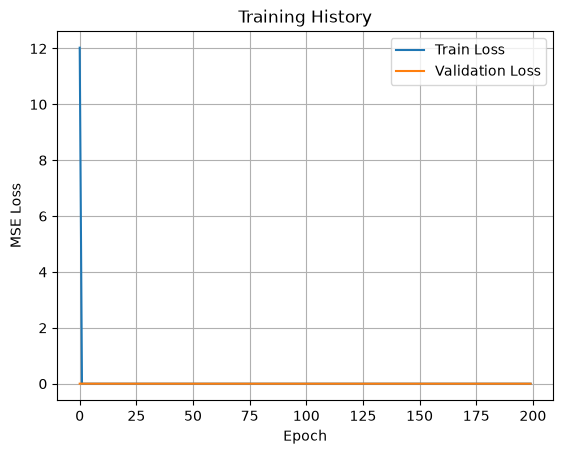

In [62]:

from pathlib import Path
from contextlib import nullcontext

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader


# ======================================
# 1. 配置
# ======================================

SEED = 42
BATCH_SIZE = 4
NUM_EPOCHS = 200
LEARNING_RATE = 0.01

USE_AMP = False

SAVE_PATH = Path("best_model.pth")

torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# AMP 只在 CUDA 环境下启用
amp_enabled = USE_AMP and device.type == "cuda"

# 支持 BF16 时优先使用 BF16
if amp_enabled:
    amp_dtype = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )
else:
    amp_dtype = torch.float32

# 只有 FP16 需要 GradScaler
use_scaler = amp_enabled and amp_dtype == torch.float16

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_scaler
)

print("运行设备:", device)
print("AMP:", amp_enabled)
print("计算精度:", amp_dtype)


# ======================================
# 2. 准备数据
# ======================================

train_x = torch.linspace(0, 10, 20).unsqueeze(1)
train_y = 2 * train_x + 1

val_x = torch.tensor([
    [0.5], [2.5], [4.5], [6.5], [8.5]
])
val_y = 2 * val_x + 1

test_x = torch.tensor([
    [1.5], [3.5], [5.5], [7.5], [9.5]
])
test_y = 2 * test_x + 1


# ======================================
# 3. Dataset 和 DataLoader
# ======================================

train_dataset = TensorDataset(train_x, train_y)
val_dataset = TensorDataset(val_x, val_y)
test_dataset = TensorDataset(test_x, test_y)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    pin_memory=(device.type == "cuda")
)


# ======================================
# 4. 定义模型
# ======================================

class ScoreModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)

    def forward(self, x):
        return self.linear(x)


model = ScoreModel().to(device)

loss_fn = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE
)


# ======================================
# 5. AMP 上下文
# ======================================

def amp_context():
    if amp_enabled:
        return torch.autocast(
            device_type="cuda",
            dtype=amp_dtype
        )

    return nullcontext()


# ======================================
# 6. 训练一个 Epoch
# ======================================

def train_one_epoch(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch_x, batch_y in loader:

        # 数据移动到模型所在设备
        batch_x = batch_x.to(
            device,
            non_blocking=True
        )
        batch_y = batch_y.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # 自动混合精度前向传播
        with amp_context():
            prediction = model(batch_x)
            loss = loss_fn(prediction, batch_y)

        # 反向传播
        if use_scaler:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        # 统计 Batch 损失
        n = batch_x.size(0)

        total_loss += loss.item() * n
        total_samples += n

    return total_loss / total_samples


# ======================================
# 7. 验证 / 测试
# ======================================

@torch.inference_mode()
def evaluate(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    for batch_x, batch_y in loader:

        batch_x = batch_x.to(
            device,
            non_blocking=True
        )
        batch_y = batch_y.to(
            device,
            non_blocking=True
        )

        with amp_context():
            prediction = model(batch_x)
            loss = loss_fn(prediction, batch_y)

        n = batch_x.size(0)

        total_loss += loss.item() * n
        total_samples += n

    return total_loss / total_samples


# ======================================
# 8. 训练主循环
# ======================================

best_val_loss = float("inf")

train_history = []
val_history = []

for epoch in range(NUM_EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader
    )

    val_loss = evaluate(
        model,
        val_loader
    )

    train_history.append(train_loss)
    val_history.append(val_loss)

    # 保存最佳模型
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            SAVE_PATH
        )

    # 输出日志
    if (epoch + 1) % 20 == 0:

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train: {train_loss:.6f} | "
            f"Val: {val_loss:.6f}"
        )


# ======================================
# 9. 加载最佳模型
# ======================================

best_model = ScoreModel().to(device)

state = torch.load(
    SAVE_PATH,
    map_location=device,
    weights_only=True
)

best_model.load_state_dict(state)
best_model.eval()


# ======================================
# 10. 测试
# ======================================

test_loss = evaluate(
    best_model,
    test_loader
)

print("\n训练完成")
print("最佳验证 Loss:", best_val_loss)
print("测试 Loss:", test_loss)

print(
    "权重 w:",
    best_model.linear.weight.item()
)

print(
    "偏置 b:",
    best_model.linear.bias.item()
)


# ======================================
# 11. 预测新数据
# ======================================

new_x = torch.tensor(
    [[12.0]],
    device=device
)

with torch.inference_mode():
    result = best_model(new_x)

print("输入 12 的预测结果:", result.item())


# ======================================
# 12. 绘制 Loss 曲线
# ======================================

import matplotlib.pyplot as plt

plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training History")
plt.legend()
plt.grid(True)

plt.show()


In [61]:
# 查看cuda显存

import torch

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated()

    reserved = torch.cuda.memory_reserved()

    print("已分配显存:", allocated / 1024**2, "MiB")
    print("已保留显存:", reserved / 1024**2, "MiB")

    free, total = torch.cuda.mem_get_info()

    print(f"GPU 总显存: {total / 1024**3:.2f} GiB")
    print(f"GPU 剩余显存: {free / 1024**3:.2f} GiB")
    print(f"GPU 已使用显存: {(total-free) / 1024**3:.2f} GiB")

已分配显存: 0.00927734375 MiB
已保留显存: 22.0 MiB
GPU 总显存: 5.67 GiB
GPU 剩余显存: 0.52 GiB
GPU 已使用显存: 5.15 GiB


In [ ]:
# 把 GPU、AMP、梯度累积整合起来


import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from contextlib import nullcontext

# =====================================
# 1. 随机种子
# =====================================

torch.manual_seed(42)


# =====================================
# 2. 自动选择设备
# =====================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("当前设备:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# =====================================
# 3. 设置 AMP
# =====================================

use_amp = device.type == "cuda"

if use_amp:
    amp_dtype = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )
else:
    amp_dtype = torch.float32

# FP16 使用梯度缩放
use_scaler = use_amp and amp_dtype == torch.float16

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_scaler
)

print("AMP 启用:", use_amp)
print("AMP 类型:", amp_dtype)


# =====================================
# 4. 创建数据
# =====================================

x = torch.linspace(0, 10, 100).unsqueeze(1)
y = 2 * x + 1

dataset = TensorDataset(x, y)

micro_batch_size = 4
accumulation_steps = 4

loader = DataLoader(
    dataset,
    batch_size=micro_batch_size,
    shuffle=True
)


# =====================================
# 5. 定义模型
# =====================================

class MyModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)


model = MyModel().to(device)


# =====================================
# 6. 损失函数与优化器
# =====================================

loss_fn = nn.MSELoss(reduction="sum")

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)


# =====================================
# 7. 开始训练
# =====================================

num_epochs = 100

for epoch in range(num_epochs):

    model.train()

    total_loss = 0.0
    total_samples = 0

    optimizer.zero_grad()

    group_samples = 0

    for batch_index, (batch_x, batch_y) in enumerate(loader):

        # 将数据移动到 GPU / CPU
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # 创建 AMP 上下文
        if use_amp:
            amp_context = torch.autocast(
                device_type="cuda",
                dtype=amp_dtype
            )
        else:
            amp_context = nullcontext()

        # 前向传播与损失计算
        with amp_context:

            prediction = model(batch_x)

            # 使用 sum，后面按照真实样本数归一化
            loss = loss_fn(prediction, batch_y)

        # 累计未归一化损失
        total_loss += loss.detach().item()
        total_samples += batch_x.size(0)

        # 反向传播，累积梯度
        scaler.scale(loss).backward()

        group_samples += batch_x.size(0)

        # 判断是否到达更新时机
        is_update_step = (
            (batch_index + 1) % accumulation_steps == 0
            or
            (batch_index + 1) == len(loader)
        )

        if is_update_step:

            # 先恢复 FP16 缩放后的梯度
            scaler.unscale_(optimizer)

            # 按当前累积组真实样本数求平均
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.div_(group_samples)

            # 更新参数
            scaler.step(optimizer)
            scaler.update()

            # 清空梯度，开始下一组
            optimizer.zero_grad()

            group_samples = 0

    epoch_loss = total_loss / total_samples

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d} | "
            f"Loss: {epoch_loss:.6f}"
        )


# =====================================
# 8. 保存模型
# =====================================

torch.save(
    model.state_dict(),
    "gpu_model.pth"
)

print("模型已保存")


# =====================================
# 9. 重新加载模型
# =====================================

loaded_model = MyModel().to(device)

state = torch.load(
    "gpu_model.pth",
    map_location=device,
    weights_only=True
)

loaded_model.load_state_dict(state)

loaded_model.eval()


# =====================================
# 10. 预测
# =====================================

test_x = torch.tensor([[12.0]]).to(device)

with torch.no_grad():

    result = loaded_model(test_x)

print("输入 12，预测:", result.item())


# =====================================
# 11. 显存统计
# =====================================

if device.type == "cuda":

    print(
        "峰值 PyTorch 已分配显存 (MiB):",
        torch.cuda.max_memory_allocated() / 1024**2
    )


In [63]:

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# =====================================
# 1. 设置随机种子和设备
# =====================================

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("当前设备:", device)


# =====================================
# 2. 生成三分类数据
# =====================================

samples_per_class = 100

centers = torch.tensor([
    [-2.0, -2.0],
    [ 2.0, -2.0],
    [ 0.0,  2.0]
])

train_features = []
train_labels = []

val_features = []
val_labels = []

test_features = []
test_labels = []

for class_id in range(3):

    center = centers[class_id]

    # 每类生成 100 条二维数据
    noise = torch.randn(100, 2) * 0.7
    class_x = center + noise

    # 每类 100 个标签
    class_y = torch.full(
        (100,),
        class_id,
        dtype=torch.long
    )

    # 打乱当前类别的数据
    indices = torch.randperm(100)

    class_x = class_x[indices]
    class_y = class_y[indices]

    # 60 条训练数据
    train_features.append(class_x[:60])
    train_labels.append(class_y[:60])

    # 20 条验证数据
    val_features.append(class_x[60:80])
    val_labels.append(class_y[60:80])

    # 20 条测试数据
    test_features.append(class_x[80:])
    test_labels.append(class_y[80:])


# =====================================
# 3. 拼接数据
# =====================================

train_x = torch.cat(train_features, dim=0)
train_y = torch.cat(train_labels, dim=0)

val_x = torch.cat(val_features, dim=0)
val_y = torch.cat(val_labels, dim=0)

test_x = torch.cat(test_features, dim=0)
test_y = torch.cat(test_labels, dim=0)

print("训练数据形状:", train_x.shape)
print("训练标签形状:", train_y.shape)
print("验证数据形状:", val_x.shape)
print("测试数据形状:", test_x.shape)


# =====================================
# 4. 创建 Dataset 和 DataLoader
# =====================================

train_dataset = TensorDataset(train_x, train_y)
val_dataset = TensorDataset(val_x, val_y)
test_dataset = TensorDataset(test_x, test_y)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)


# =====================================
# 5. 定义多层分类神经网络
# =====================================

class Classifier(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )

    def forward(self, x):
        return self.net(x)


# =====================================
# 6. 创建模型、Loss、Optimizer
# =====================================

model = Classifier().to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

print(
    "模型参数数量:",
    sum(p.numel() for p in model.parameters())
)


# =====================================
# 7. 训练和验证
# =====================================

num_epochs = 100
best_val_loss = float("inf")

for epoch in range(num_epochs):

    # ---------- 训练阶段 ----------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # 前向传播，输出 Logits
        logits = model(batch_x)

        # 计算交叉熵损失
        loss = loss_fn(logits, batch_y)

        # 清空梯度
        optimizer.zero_grad()

        # 反向传播
        loss.backward()

        # 更新参数
        optimizer.step()

        # 累积 Loss
        batch_size = batch_x.size(0)

        train_loss_sum += loss.item() * batch_size

        # 预测类别
        predictions = logits.argmax(dim=1)

        # 统计正确数量
        train_correct += (
            predictions == batch_y
        ).sum().item()

        train_total += batch_size

    train_loss = train_loss_sum / train_total

    train_accuracy = train_correct / train_total


    # ---------- 验证阶段 ----------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for batch_x, batch_y in val_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_x)

            loss = loss_fn(logits, batch_y)

            batch_size = batch_x.size(0)

            val_loss_sum += loss.item() * batch_size

            predictions = logits.argmax(dim=1)

            val_correct += (
                predictions == batch_y
            ).sum().item()

            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total


    # ---------- 保存最佳模型 ----------
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        torch.save(
            model.state_dict(),
            "best_classifier.pth"
        )


    # ---------- 输出训练信息 ----------
    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch + 1:3d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2%} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2%}"
        )


# =====================================
# 8. 加载验证 Loss 最低的模型
# =====================================

best_model = Classifier().to(device)

state = torch.load(
    "best_classifier.pth",
    map_location=device,
    weights_only=True
)

best_model.load_state_dict(state)
best_model.eval()


# =====================================
# 9. 测试集评估
# =====================================

test_loss_sum = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        logits = best_model(batch_x)

        loss = loss_fn(logits, batch_y)

        batch_size = batch_x.size(0)

        test_loss_sum += loss.item() * batch_size

        predictions = logits.argmax(dim=1)

        test_correct += (
            predictions == batch_y
        ).sum().item()

        test_total += batch_size

test_loss = test_loss_sum / test_total
test_accuracy = test_correct / test_total

print("\n最终测试结果")
print("Test Loss:", test_loss)
print("Test Accuracy:", f"{test_accuracy:.2%}")


# =====================================
# 10. 预测一条新数据
# =====================================

new_x = torch.tensor([
    [2.0, -2.0]
], dtype=torch.float32).to(device)

with torch.no_grad():

    logits = best_model(new_x)

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    predicted_class = logits.argmax(
        dim=1
    )

print("\n新数据:", new_x.cpu().tolist())
print("Logits:", logits.cpu().tolist())
print("类别概率:", probabilities.cpu().tolist())
print("预测类别:", predicted_class.item())


当前设备: cuda
训练数据形状: torch.Size([180, 2])
训练标签形状: torch.Size([180])
验证数据形状: torch.Size([60, 2])
测试数据形状: torch.Size([60, 2])
模型参数数量: 371
Epoch  10 | Train Loss: 0.0009 | Train Acc: 100.00% | Val Loss: 0.0001 | Val Acc: 100.00%
Epoch  20 | Train Loss: 0.0004 | Train Acc: 100.00% | Val Loss: 0.0001 | Val Acc: 100.00%
Epoch  30 | Train Loss: 0.0002 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch  40 | Train Loss: 0.0001 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch  50 | Train Loss: 0.0001 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch  60 | Train Loss: 0.0001 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch  70 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch  80 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch  90 | Train Loss: 0.0000 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00%
Epoch 100 | Train Loss: 0.0000 | Train Acc: 100.00% | Va

In [84]:
# 神经网络计算分类
import torch
from torch import nn

model = nn.Linear(2,3)

x = torch.tensor([2.0, 3.0])

logits = model(x)
logits

model.weight, model.bias

(Parameter containing:
 tensor([[-0.6780, -0.2224],
         [-0.6165, -0.3172],
         [ 0.3003, -0.5067]], requires_grad=True),
 Parameter containing:
 tensor([-0.6115,  0.5056,  0.3775], requires_grad=True))

In [85]:
# softmax 将一组实数转换为总和为1的概率分布
import torch

logits = torch.tensor([[2.0, 1.0, 0.1]])

probs = torch.softmax(logits, dim=1)

print(probs)

tensor([[0.6590, 0.2424, 0.0986]])


In [ ]:
# 	Sigmoid	Softmax
# 典型任务	二分类、多标签分类	多类别互斥分类
# 输出	每个类别独立的概率	所有类别的概率分布
# 总和必须为 1	否	是
# 常见损失	BCEWithLogitsLoss	CrossEntropyLoss

In [86]:
import torch
from torch import nn

logits = torch.tensor([
    [2.0, 1.0, 0.1]
])

target = torch.tensor([0])

criterion = nn.CrossEntropyLoss()

loss = criterion(logits, target)

print(loss.item())

0.4170299470424652


In [8]:
# 目标：根据两个特征，把样本分类为三个类别。
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 设置随机种子
torch.manual_seed(42)

# 选择设备
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 构建三类数据
class0 = torch.randn(100, 2) * 0.4 + torch.tensor([0.0, 0.0])
class1 = torch.randn(100, 2) * 0.4 + torch.tensor([3.0, 0.0])
class2 = torch.randn(100, 2) * 0.4 + torch.tensor([1.5, 3.0])

# 拼接输入
x = torch.cat([class0, class1, class2], dim=0)

# 构建标签
y = torch.cat(
    [
        torch.zeros(100, dtype=torch.long),
        torch.ones(100, dtype=torch.long),
        torch.full((100,), 2, dtype=torch.long)
    ],
    dim=0
)

# 创建DataSet
dataset = TensorDataset(x, y)

# 创建DataLoader
dataloader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True,
)

# 创建神经网络
model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 3),
).to(device)

# 损失函数
criterion = nn.CrossEntropyLoss()

# 优化器
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 100
# 训练
for epoch in range(epochs):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_x, batch_y in dataloader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        # 清空梯度
        optimizer.zero_grad()

        # 前向传播
        logits = model(batch_x)

        # 计算损失
        loss = criterion(logits, batch_y)

        # 反向传播
        loss.backward()

        # 更新参数
        optimizer.step()

        # 统计损失
        total_loss += loss.item() * batch_x.size(0)

        # 预测类别
        prediction = torch.argmax(logits, dim=1)

        # 统计准确数量
        correct += (prediction == batch_y).sum().item()

        total += batch_y.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1} | "
            f"Train Loss: {avg_loss:.4f} | "
            f"Train Acc: {accuracy:.2%} | "
        )
.,/
# 验证样本
model.eval()

new_x = torch.tensor([
    [0.1, 0.2],
    [3.1, 0.1],
    [1.5, 3.2]
], device=device)

with torch.no_grad():
    logits = model(new_x)
    probs = torch.softmax(logits, dim=1)
    predictions = torch.argmax(logits, dim=1)

print("预测概率:")
print(probs)

print("预测类别:")
print(predictions)

Epoch 10 | Train Loss: 0.0010 | Train Acc: 100.00% | 
Epoch 20 | Train Loss: 0.0003 | Train Acc: 100.00% | 
Epoch 30 | Train Loss: 0.0001 | Train Acc: 100.00% | 
Epoch 40 | Train Loss: 0.0001 | Train Acc: 100.00% | 
Epoch 50 | Train Loss: 0.0000 | Train Acc: 100.00% | 
Epoch 60 | Train Loss: 0.0000 | Train Acc: 100.00% | 
Epoch 70 | Train Loss: 0.0000 | Train Acc: 100.00% | 
Epoch 80 | Train Loss: 0.0000 | Train Acc: 100.00% | 
Epoch 90 | Train Loss: 0.0000 | Train Acc: 100.00% | 
Epoch 100 | Train Loss: 0.0000 | Train Acc: 100.00% | 
预测概率:
tensor([[1.0000e+00, 3.1597e-09, 4.6444e-10],
        [3.3389e-08, 1.0000e+00, 2.7098e-10],
        [2.6719e-06, 3.7967e-06, 9.9999e-01]], device='cuda:0')
预测类别:
tensor([0, 1, 2], device='cuda:0')


In [4]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Linear(2, 16),
    nn.ReLU(),
    nn.Linear(16, 16),
    nn.ReLU(),
    nn.Linear(16, 3),
)

# 一个样本，两个特征
x = torch.tensor([[2.0, 3.0]])

print("原始输入:", x.shape)

for i, layer in enumerate(model):
    x = layer(x)
    print(f"第 {i} 层 {layer}: {x.shape}")

原始输入: torch.Size([1, 2])
第 0 层 Linear(in_features=2, out_features=16, bias=True): torch.Size([1, 16])
第 1 层 ReLU(): torch.Size([1, 16])
第 2 层 Linear(in_features=16, out_features=16, bias=True): torch.Size([1, 16])
第 3 层 ReLU(): torch.Size([1, 16])
第 4 层 Linear(in_features=16, out_features=3, bias=True): torch.Size([1, 3])


In [11]:
# Embedding

import torch
from torch import nn

embedding = nn.Embedding(
    num_embeddings=7,
    embedding_dim=4
)

input_ids = torch.tensor([2,3,4], dtype=torch.long)

output = embedding(input_ids)

print("Embedding 权重形状:", embedding.weight.shape)
print("输入形状:", input_ids.shape)
print("输出形状:", output.shape)
print(output)
print(embedding.weight)

Embedding 权重形状: torch.Size([7, 4])
输入形状: torch.Size([3])
输出形状: torch.Size([3, 4])
tensor([[-1.2317, -1.2464, -1.4996, -0.5404],
        [ 0.6420, -0.8497, -0.6987, -0.2052],
        [-0.7812,  0.6873,  0.7836, -1.1109]], grad_fn=<EmbeddingBackward0>)
Parameter containing:
tensor([[ 0.5238,  0.7531, -0.2219,  0.5819],
        [-1.9369,  0.7781, -1.4069,  0.4058],
        [-1.2317, -1.2464, -1.4996, -0.5404],
        [ 0.6420, -0.8497, -0.6987, -0.2052],
        [-0.7812,  0.6873,  0.7836, -1.1109],
        [-0.0321, -0.9898, -0.6022, -0.7153],
        [-0.4674,  0.5514,  2.6549,  1.0582]], requires_grad=True)


In [12]:
import torch
from torch import nn

embedding = nn.Embedding(7, 4)

weights = torch.tensor([
    [0.0, 0.0,  0.0,  0.0],
    [0.1, 0.1,  0.1,  0.1],
    [0.5, 0.2,  0.1,  0.3],
    [0.2, 0.8, -0.1,  0.5],
    [0.9, 0.1,  0.4, -0.2],
    [0.3, 0.7,  0.2,  0.1],
    [0.6, 0.4,  0.5,  0.2]
])

with torch.no_grad():
    embedding.weight.copy_(weights)

input_ids = torch.tensor([2, 3, 4])

output = embedding(input_ids)

print(output)

tensor([[ 0.5000,  0.2000,  0.1000,  0.3000],
        [ 0.2000,  0.8000, -0.1000,  0.5000],
        [ 0.9000,  0.1000,  0.4000, -0.2000]], grad_fn=<EmbeddingBackward0>)


In [13]:

import math
import torch

Q = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0]
])

K = Q.clone()
V = Q.clone()

# 第一步：计算注意力分数
scores = Q @ K.T

# 第二步：缩放
scores = scores / math.sqrt(K.shape[-1])

# 第三步：Softmax
weights = torch.softmax(scores, dim=-1)

# 第四步：加权求和
output = weights @ V

print("Scores:")
print(scores)

print("Attention weights:")
print(weights)

print("Output:")
print(output)


Scores:
tensor([[0.7071, 0.0000],
        [0.0000, 0.7071]])
Attention weights:
tensor([[0.6698, 0.3302],
        [0.3302, 0.6698]])
Output:
tensor([[0.6698, 0.3302],
        [0.3302, 0.6698]])
